[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Maxencegu/python-datascience-m1/blob/main/assignments/td07_mp1_etude_de_cas_et_mini_projet/td07_enonce.ipynb)

In [ ]:
# @title 📋 Feuille de présence (remplir maintenant)
from IPython.display import Image, display, HTML

display(HTML('<h3 style="font-family:sans-serif;">📋 Feuille de présence</h3>'))
display(Image(url="https://raw.githubusercontent.com/Maxencegu/python-datascience-m1/main/assignments/td07_mp1_etude_de_cas_et_mini_projet/assets/qr_td07_presence.png", width=250))
display(HTML('<a href="https://forms.gle/8DqGDEdf2ggimTzx6" target="_blank"><button style="font-size:15px;padding:8px 16px;margin-top:8px;cursor:pointer;">Ouvrir le formulaire</button></a>'))

# **Introduction**

Au TD précédent, vous avez maîtrisé la **logique**, les **flux de contrôle** et les **boucles**.
Vous savez filtrer un DataFrame avec des conditions, itérer sur des données et construire
des traitements automatiques — autant d'outils que vous allez mobiliser intensément aujourd'hui.

Mais que faire quand on ne connaît pas à l'avance le résultat d'un phénomène ?
Comment modéliser une situation qui dépend du hasard — une décision aléatoire,
un accident, une trajectoire imprévisible — sans recourir à des formules mathématiques complexes ?

La réponse : **simuler**. Répéter l'expérience des milliers de fois et observer ce qui se passe.
C'est l'approche dite des **statistiques façon hacker** — simple, puissante, et universelle.

**NumPy** expose un module `np.random` qui permet de générer des nombres aléatoires
et de reproduire exactement les mêmes résultats grâce à une **graine** (`seed`).

La **marche aléatoire** (*random walk*) est un modèle classique en économie et en finance :
à chaque pas, on avance ou recule selon le résultat d'un tirage aléatoire.
Elle modélise aussi bien le cours d'une action que la diffusion d'un gaz.

La **simulation Monte-Carlo** consiste à répéter une expérience aléatoire un grand nombre
de fois pour estimer une probabilité à partir des résultats observés — sans calcul analytique.

Dans ce TD, vous apprendrez à :
- générer des nombres aléatoires avec `np.random.rand()` et `np.random.randint()` ;
- fixer une graine pour rendre vos simulations reproductibles avec `np.random.seed()` ;
- coder une marche aléatoire pas à pas avec une boucle `for` ;
- visualiser une trajectoire aléatoire avec Matplotlib ;
- estimer une probabilité par simulation (méthode Monte-Carlo) ;
- appliquer l'ensemble de ces compétences sur un jeu de données réel dans le **mini-projet 1**.

À l'issue de cette séance, vous serez capables de modéliser un phénomène aléatoire,
d'en simuler des milliers de réalisations, et d'en tirer une conclusion statistique
— compétences directement mobilisables en économie, finance et data science.

In [ ]:
# @title Configuration des ressources (ne pas modifier)
from IPython.display import Image, display, HTML

BASE_URL = "https://raw.githubusercontent.com/Maxencegu/python-datascience-m1/main/assignments/td07_mp1_etude_de_cas_et_mini_projet/images/"

def afficher_infographie(nom_fichier, largeur=1300):
    display(Image(url=BASE_URL + nom_fichier, width=largeur))

In [ ]:
# @title Infographie — Workflow Complet du TD
afficher_infographie("13_workflow_complet_td_pro.png")

# **1. Étude de cas : Statistiques sur les pirates informatiques**

Ce chapitre vous permettra de mettre en pratique tous les concepts que vous avez appris dans ce cours. Vous utiliserez les statistiques des hackers pour calculer vos chances de gagner un pari. Utilisez des générateurs de nombres aléatoires, des boucles et Matplotlib pour gagner en compétitivité.

## **1.1 Nombres aléatoires**

In [ ]:
# @title Infographie — Nombres Aléatoires
afficher_infographie("01_nombres_aleatoires_pro.png")

---
---
### **Exercice**

Le module `np.random` contient tout ce dont vous avez besoin pour simuler des événements aléatoires.

- `np.random.seed(n)` — fixe la graine pour des résultats reproductibles
- `np.random.rand()` — génère un flottant aléatoire entre 0 et 1

---
### **Instructions**
1. Importez `numpy` sous l'alias `np`.
2. Fixez la graine aléatoire à `123`.
3. Générez un flottant aléatoire avec `rand()` et affichez-le.

In [ ]:
# Import numpy as np
import numpy as np

# Set the seed
np.random.seed(123)

# Generate and print random float
print(np.random.rand())

0.6964691855978616


---
---
### **Exercice**

`np.random.randint(low, high)` génère un entier aléatoire dans l'intervalle **[low, high[** (high exclu) :

```python
np.random.randint(4, 8)   # → 4, 5, 6 ou 7
```
---
### **Instructions**

1. Utilisez randint() pour simuler un lancer de dé (entier entre 1 et 6 inclus) et affichez le résultat.
2. Relancez le dé une deuxième fois et affichez à nouveau le résultat.

In [ ]:
# Import numpy and set seed
import numpy as np
np.random.seed(123)

# Use randint() to simulate a dice
print(np.random.randint(1, 7))

# Use randint() again
print(np.random.randint(1, 7))

6
3


---
---
### **Exercice**

Votre prochaine action dépend du résultat du dé. Vous partez de la marche 50.

| Résultat du dé | Action |
|---|---|
| 1 ou 2 | Descendre d'une marche |
| 3, 4 ou 5 | Monter d'une marche |
| 6 | Relancer le dé → monter d'autant de marches |

La graine a déjà été fixée à l'exercice précédent : ne la refixez pas.

---
### **Instructions**
1. Lancez le dé avec `randint()` et stockez le résultat dans `dice`.
2. Complétez le `if-elif-else` selon les règles du tableau.
3. Affichez `dice` et `step`.

In [ ]:
# NumPy is imported, seed is set (ne refixez pas la graine)
import numpy as np

# Starting step
step = 50

# Roll the dice
dice = np.random.randint(1, 7)

# Finish the control construct
if dice <= 2 :
    step = step - 1
elif dice <= 5 :
    step = step + 1
else :
    step = step + np.random.randint(1,7)

# Print out dice and step
print(dice)
print(step)

5
51


La borne supérieure de `randint(1, 7)` est exclue, ce qui donne les six faces du dé. Cette cellule poursuit la séquence de tirages de la cellule précédente.

## **1.2 Marche aléatoire**

In [ ]:
# @title Infographie — Marche aléatoire
afficher_infographie("02_marche_aleatoire_pro.png")

---
---
### **Exercice**

Vous allez simuler une marche aléatoire en plaçant la logique de l'exercice précédent dans une boucle `for`. À chaque itération, la position suivante est calculée à partir de la position actuelle.

**Rappel des règles :**
- Dé 1 ou 2 → descendre d'une marche
- Dé 3, 4 ou 5 → monter d'une marche
- Dé 6 → relancer et monter d'autant de marches

---
### **Instructions**
1. Importez `numpy` sous l'alias `np`, fixez la graine à `123`, puis créez `random_walk`, une liste contenant uniquement `0` (position de départ).
2. Complétez la boucle `for` pour qu'elle s'exécute **100 fois**.
3. À chaque tour, récupérez le dernier élément de `random_walk` comme valeur de `step`.
4. Affichez `random_walk` après la boucle.

In [ ]:
# NumPy and seed
import numpy as np
np.random.seed(123)

# Initialize random_walk
random_walk = [0]

# Complete the for loop
for x in range(100) :
    # Set step: last element in random_walk
    step = random_walk[-1]

    # Roll the dice
    dice = np.random.randint(1, 7)

    # Determine next step
    if dice <= 2:
        step = step - 1
    elif dice <= 5:
        step = step + 1
    else:
        step = step + np.random.randint(1,7)

    # append next_step to random_walk
    random_walk.append(step)

# Print random_walk
print(random_walk)

[0, 3, 4, 5, 4, 5, 6, 7, 6, 5, 4, 3, 2, 1, 0, -1, 0, 5, 4, 3, 4, 3, 4, 5, 6, 7, 8, 7, 8, 7, 8, 9, 10, 11, 10, 14, 15, 14, 15, 14, 15, 16, 17, 18, 19, 20, 21, 24, 25, 26, 27, 32, 33, 37, 38, 37, 38, 39, 38, 39, 40, 42, 43, 44, 43, 42, 43, 44, 43, 42, 43, 44, 46, 45, 44, 45, 44, 45, 46, 47, 49, 48, 49, 50, 51, 52, 53, 52, 51, 52, 51, 52, 53, 52, 55, 56, 57, 58, 57, 58, 59]


---
---
### **Exercice**

Dans la simulation actuelle, `step` peut devenir négatif — ce qui est impossible dans l'Empire State Building. Il faut s'assurer que la position ne descende jamais en dessous de `0`.

`max()` avec deux arguments renvoie le plus grand des deux :

```python
x = max(10, x - 1)   # x ne descendra jamais sous 10
```

---
### **Instructions**

Remplacez les ____ puis modifiez la ligne step = step - 1 pour utiliser max() et empêcher step de passer en dessous de 0.

In [ ]:
# NumPy and seed
import numpy as np
np.random.seed(123)

# Initialize random_walk
random_walk = [0]

for x in range(100) :
    step = random_walk[-1]
    dice = np.random.randint(1, 7)

    if dice <= 2:
        # Replace below: use max to make sure step can't go below 0
        step = max(0, step - 1)
    elif dice <= 5:
        step = step + 1
    else:
        step = step + np.random.randint(1,7)

    random_walk.append(step)

print(random_walk)

[0, 3, 4, 5, 4, 5, 6, 7, 6, 5, 4, 3, 2, 1, 0, 0, 1, 6, 5, 4, 5, 4, 5, 6, 7, 8, 9, 8, 9, 8, 9, 10, 11, 12, 11, 15, 16, 15, 16, 15, 16, 17, 18, 19, 20, 21, 22, 25, 26, 27, 28, 33, 34, 38, 39, 38, 39, 40, 39, 40, 41, 43, 44, 45, 44, 43, 44, 45, 44, 43, 44, 45, 47, 46, 45, 46, 45, 46, 47, 48, 50, 49, 50, 51, 52, 53, 54, 53, 52, 53, 52, 53, 54, 53, 56, 57, 58, 59, 58, 59, 60]


Chaque liste contient 101 positions. La première est le départ, puis chaque tour ajoute la position actualisée. La fonction `max(0, step - 1)` maintient la position à 0 quand le dé indique une descente depuis le rez-de-chaussée.

---
---
### **Exercice**

Vous souvenez-vous que vous pouviez utiliser matplotlib pour construire un graphique linéaire ?

```python
import matplotlib.pyplot as plt
plt.plot(x, y)
plt.show()
```

La première liste transmise est placée sur l'axe x et la deuxième sur l'axe y.

Si vous ne passez qu'un seul argument, Python saura quoi faire et utilisera l'index de la liste pour l'inscrire sur l'axe x, et les valeurs de la liste sur l'axe y.

---
### **Instructions**

Ajoutez quelques lignes de code après la boucle for :
1. Importez matplotlib.pyplot en tant que plt.
2. Utilisez plt.plot() pour tracer random_walk.
3. Terminez avec plt.show() pour afficher le tracé.

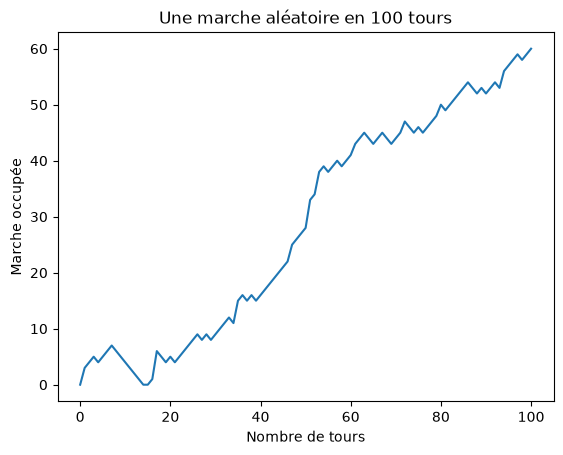

In [ ]:
# NumPy and seed
import numpy as np
np.random.seed(123)

# Initialization
random_walk = [0]

for x in range(100) :
    step = random_walk[-1]
    dice = np.random.randint(1, 7)

    if dice <= 2:
        step = max(0, step - 1)
    elif dice <= 5:
        step = step + 1
    else:
        step = step + np.random.randint(1,7)

    random_walk.append(step)

# Import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

# Plot random_walk
plt.figure()
plt.plot(random_walk)
plt.xlabel("Nombre de tours")
plt.ylabel("Marche occupée")
plt.title("Une marche aléatoire en 100 tours")

# Show the plot
plt.show()

## **1.3 Distribution**

In [ ]:
# @title Infographie — Simulation d'une distribution
afficher_infographie("03_distribution_simulation_pro.png")

---
---
### **Exercice**

Pour estimer la probabilité de gagner le pari, il faut simuler la marche aléatoire **plusieurs fois** et collecter tous les résultats. On ajoute une boucle `for` externe autour du code existant.

---
### **Instructions**
1. Complétez la boucle externe pour simuler la marche **5 fois**.
2. Après chaque marche complète, ajoutez `random_walk` à `all_walks`.
3. Affichez `all_walks` après la boucle externe.

In [ ]:
# NumPy and seed
import numpy as np
np.random.seed(123)

# Initialize all_walks (don't change this line)
all_walks = []

# Simulate random walk five times
for i in range(5) :

    # Code from before
    random_walk = [0]
    for x in range(100) :
        step = random_walk[-1]
        dice = np.random.randint(1, 7)

        if dice <= 2:
            step = max(0, step - 1)
        elif dice <= 5:
            step = step + 1
        else:
            step = step + np.random.randint(1,7)
        random_walk.append(step)

    # Append random_walk to all_walks
    all_walks.append(random_walk)

# Print all_walks
print(all_walks)

[[0, 3, 4, 5, 4, 5, 6, 7, 6, 5, 4, 3, 2, 1, 0, 0, 1, 6, 5, 4, 5, 4, 5, 6, 7, 8, 9, 8, 9, 8, 9, 10, 11, 12, 11, 15, 16, 15, 16, 15, 16, 17, 18, 19, 20, 21, 22, 25, 26, 27, 28, 33, 34, 38, 39, 38, 39, 40, 39, 40, 41, 43, 44, 45, 44, 43, 44, 45, 44, 43, 44, 45, 47, 46, 45, 46, 45, 46, 47, 48, 50, 49, 50, 51, 52, 53, 54, 53, 52, 53, 52, 53, 54, 53, 56, 57, 58, 59, 58, 59, 60], [0, 4, 3, 2, 4, 3, 4, 6, 7, 8, 13, 12, 13, 14, 15, 16, 17, 16, 21, 22, 23, 24, 23, 22, 21, 20, 19, 20, 21, 22, 28, 27, 26, 25, 26, 27, 28, 27, 28, 29, 28, 33, 34, 33, 32, 31, 30, 31, 30, 29, 31, 32, 35, 36, 38, 39, 40, 41, 40, 39, 40, 41, 42, 43, 42, 43, 44, 45, 48, 49, 50, 49, 50, 49, 50, 51, 52, 56, 55, 54, 55, 56, 57, 56, 57, 56, 57, 59, 64, 63, 64, 65, 66, 67, 68, 69, 68, 69, 70, 71, 73], [0, 2, 1, 2, 3, 6, 5, 6, 5, 6, 7, 8, 7, 8, 7, 8, 9, 11, 10, 9, 10, 11, 10, 12, 13, 14, 15, 16, 17, 18, 17, 18, 19, 24, 25, 24, 23, 22, 21, 22, 23, 24, 29, 30, 29, 30, 31, 32, 33, 34, 35, 34, 33, 34, 33, 39, 38, 39, 38, 39, 38, 3

---
---
### **Exercice**

`all_walks` est une liste de listes. Convertie en tableau NumPy, elle a la forme `(5, 101)` : 5 lignes (marches) × 101 colonnes (positions). Pour tracer chaque marche comme une courbe, `plt.plot()` a besoin que **chaque colonne** représente un lancer — il faut donc transposer le tableau.

---
### **Instructions**
1. Convertissez `all_walks` en tableau NumPy `np_aw` avec `np.array()`.
2. Tracez `np_aw` avec `plt.plot()` et `plt.show()`. Est-ce que ça fonctionne immédiatement ?
3. Transposez `np_aw` avec `np.transpose()` et stockez le résultat dans `np_aw_t`.
4. Tracez `np_aw_t` avec `plt.plot()` et `plt.show()`. Le résultat est-il meilleur ?

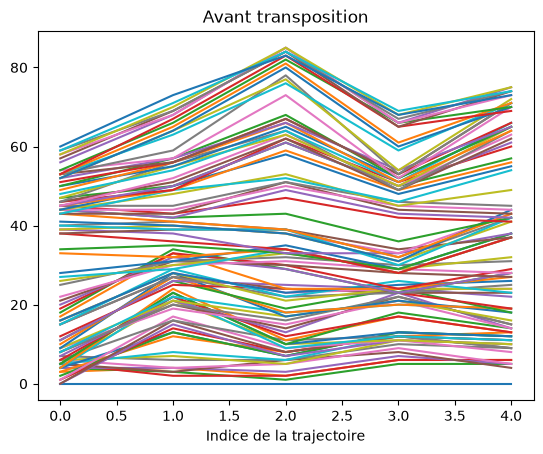

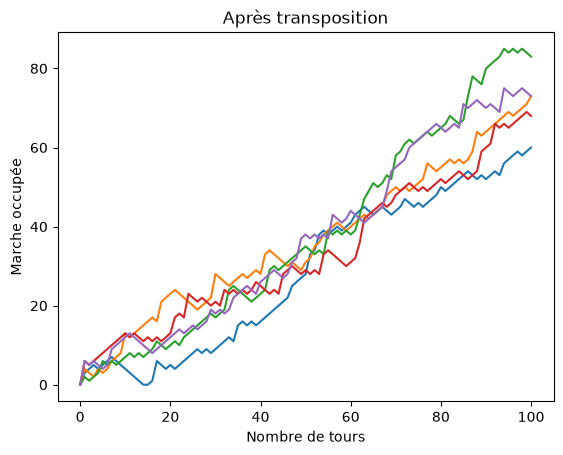

In [ ]:
# Numpy, Matplotlib and seed
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(123)

# initialize and populate all_walks
all_walks = []
for i in range(5) :
    random_walk = [0]
    for x in range(100) :
        step = random_walk[-1]
        dice = np.random.randint(1, 7)
        if dice <= 2:
            step = max(0, step - 1)
        elif dice <= 5:
            step = step + 1
        else:
            step = step + np.random.randint(1,7)
        random_walk.append(step)
    all_walks.append(random_walk)

# Convert all_walks to NumPy array: np_aw
np_aw = np.array(all_walks)

# Plot np_aw and show
plt.figure()
plt.plot(np_aw)
plt.xlabel("Indice de la trajectoire")
plt.title("Avant transposition")
plt.show()

# Create a separate figure for the transposed data
plt.figure()

# Transpose np_aw: np_aw_t
np_aw_t = np.transpose(np_aw)

# Plot np_aw_t and show
plt.plot(np_aw_t)
plt.xlabel("Nombre de tours")
plt.ylabel("Marche occupée")
plt.title("Après transposition")
plt.show()

Avant transposition, Matplotlib trace 101 courbes de 5 points, car il interprète chaque colonne comme une série. Après transposition, le tableau a la forme `(101, 5)`. Chaque colonne représente alors une trajectoire entière, de la position de départ au 100ᵉ tour.

---
---
### **Exercice**

Vous avez oublié un détail : vous êtes maladroit et avez **0,1 % de chances de tomber** à chaque marche. Si vous tombez, vous repartez de la marche 0.

`np.random.rand()` génère un flottant entre 0 et 1. Si ce nombre est ≤ 0,001, vous tombez.

---
### **Instructions**
1. Modifiez `range()` pour simuler la marche **20 fois**.
2. Complétez la condition `if` : si `np.random.rand()` est ≤ `0.001`, remettez `step` à `0`.

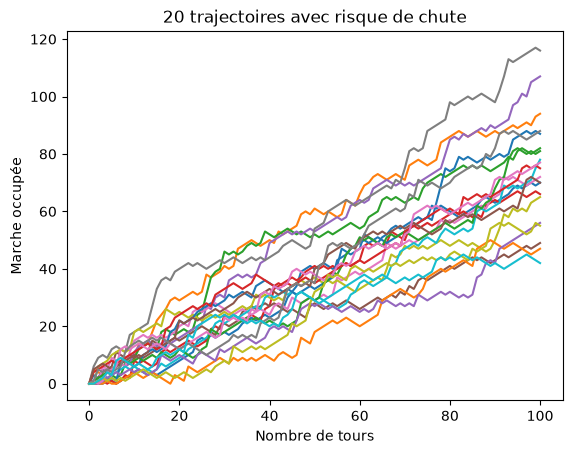

In [ ]:
# Numpy, Matplotlib and seed
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(123)

plt.figure()

# Simulate random walk 20 times
all_walks = []
for i in range(20) :
    random_walk = [0]
    for x in range(100) :
        step = random_walk[-1]
        dice = np.random.randint(1, 7)
        if dice <= 2:
            step = max(0, step - 1)
        elif dice <= 5:
            step = step + 1
        else:
            step = step + np.random.randint(1,7)

        # Implement clumsiness
        if np.random.rand() <= 0.001 :
            step = 0

        random_walk.append(step)
    all_walks.append(random_walk)

# Create and plot np_aw_t
np_aw_t = np.transpose(all_walks)
plt.plot(np_aw_t)
plt.xlabel("Nombre de tours")
plt.ylabel("Marche occupée")
plt.title("20 trajectoires avec risque de chute")
plt.show()

---
---
### **Exercice**

Pour répondre à la question principale — *quelle est la probabilité d'atteindre 60 marches ?* — vous avez besoin de la distribution des **points d'arrivée** de toutes vos simulations.

`np_aw_t` est de forme `(101, 500)` : 101 positions × 500 marches. La **dernière ligne** contient donc les 500 points d'arrivée.

---
### **Instructions**
1. Simulez la marche aléatoire **500 fois**.
2. Sélectionnez la dernière ligne de `np_aw_t` et stockez-la dans `ends`.
3. Tracez un histogramme de `ends` avec `plt.hist()` et affichez-le avec `plt.show()`.

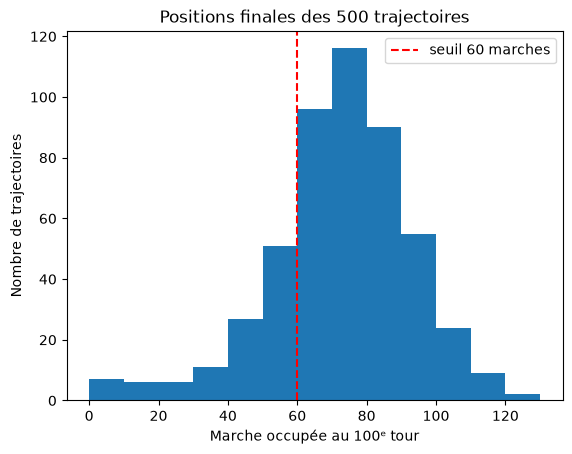

In [ ]:
# Numpy, Matplotlib and seed
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(123)

# Simulate random walk 500 times
all_walks = []
for i in range(500) :
    random_walk = [0]
    for x in range(100) :
        step = random_walk[-1]
        dice = np.random.randint(1, 7)
        if dice <= 2:
            step = max(0, step - 1)
        elif dice <= 5:
            step = step + 1
        else:
            step = step + np.random.randint(1,7)
        if np.random.rand() <= 0.001 :
            step = 0
        random_walk.append(step)
    all_walks.append(random_walk)

# Create and plot np_aw_t
np_aw_t = np.transpose(all_walks)

# Select last row from np_aw_t: ends
ends = np_aw_t[-1]

# Plot histogram of ends, display plot
plt.figure()
plt.hist(ends, bins=range(0, int(ends.max()) + 11, 10))
plt.axvline(x=60, color='red', linestyle='--', label='seuil 60 marches')
plt.legend()
plt.xlabel("Marche occupée au 100ᵉ tour")
plt.ylabel("Nombre de trajectoires")
plt.title("Positions finales des 500 trajectoires")
plt.show()

---
---
### **Exercice**

`ends` contient 500 entiers représentant le point d'arrivée de chaque simulation. Pour estimer la probabilité d'atteindre au moins 60 marches, comptez le nombre de valeurs ≥ 60 et divisez par 500.

Quelle est la probabilité estimée ?

- Choix 1 — 50 %
- Choix 2 — 60 %
- Choix 3 — 70 %
- Choix 4 — 80 %

In [ ]:
# Entrez le numéro de la bonne réponse (1, 2, 3 ou 4)
reponse = 4

In [ ]:
# @title ✅ Exécuter la cellule pour vérifier votre réponse
EXPLICATIONS = {
    1: "Incorrect. 50 % est trop bas — regardez la proportion de l'histogramme au-delà de 60.",
    2: "Incorrect. 60 % est trop bas — regardez la proportion de l'histogramme au-delà de 60.",
    3: "Incorrect. 70 % est proche mais pas le bon résultat !",
    4: "Correct! 80 % est en effet une très bonne valeur estimée.",
}

try:
    r = int(reponse)
    if isinstance(reponse, bool) or r != float(reponse):
        raise ValueError  # refuse True/False et les nombres non entiers (3.7)
    if r == 4:
        print(f"✅ Bonne réponse ({r}) : {EXPLICATIONS[r]}")
    elif r in EXPLICATIONS:
        print(f"❌ Réponse {r} incorrecte : {EXPLICATIONS[r]}")
    else:
        print(f"❌ Réponse non reconnue : attendu un nombre entre 1 et 4")
except NameError:
    print("❌ reponse n'est pas défini — attribuez un nombre à la variable reponse")
except (ValueError, TypeError):
    print(f"❌ reponse doit être un nombre (1 à 4) — valeur reçue : {reponse!r}")

✅ Bonne réponse (4) : Correct! 80 % est en effet une très bonne valeur estimée.


In [ ]:
# Calculez la proportion observée sur les 500 trajectoires.
nombre_reussites = np.count_nonzero(ends >= 60)
probabilite_estimee = nombre_reussites / ends.size
print(f"{nombre_reussites}/{ends.size} trajectoires, soit {probabilite_estimee:.1%}.")

392/500 trajectoires, soit 78.4%.


La condition `ends >= 60` compte les trajectoires qui se terminent à la marche 60 ou au-delà au 100ᵉ tour. La proportion observée est une estimation Monte-Carlo sous les règles du modèle, avec une probabilité de chute de 0,1 % par tour.

# **2. Enquête sur les films Netflix**  

Explorez les données des films Netflix et réalisez une analyse exploratoire des données pour une société de production afin de mettre en évidence des insights sur les films d’une décennie particulière.

# 🎬 Mini-projet 1 — Analyse Netflix : films des années 1990

Vous travaillez pour une société de production spécialisée dans les styles nostalgiques. Votre mission : analyser les films Netflix des années 1990 pour mieux comprendre cette décennie.

Le jeu de données `netflix_data.csv` contient à la fois des films et des séries. Les **années 1990** désignent ici les années de sortie **1990 à 1999 inclus**.

### Question 1 — La durée de film la plus fréquente

- Ne gardez que les **films** (colonne `type`) sortis de 1990 à 1999 inclus.
- Tracez un **histogramme** de la distribution de leurs durées.
- Repérez la durée la plus fréquente et enregistrez-la en minutes, sous forme d'**entier**, dans une variable nommée `duration`.
- Une lecture approchée du graphique suffit : toute valeur proche du pic est acceptée.

### Question 2 — Les films d'action courts

- Un film est **court** s'il dure **strictement moins de 90 minutes**.
- Parmi les films d'**action** (colonne `genre`) sortis de 1990 à 1999 inclus, comptez les films courts.
- Enregistrez ce nombre, sous forme d'**entier**, dans une variable nommée `short_movie_count`.
- Ici, la valeur exacte est attendue.

### Vérification et notation

Les trois cellules ✅ placées après votre code vérifient votre travail, pour **10 points chacune** :
histogramme tracé, `duration`, `short_movie_count`.

- 💡 Astuce : pour voir les valeurs uniques d'une colonne : `netflix_df['type'].unique()`
- 💡 Astuce : pour trouver la valeur la plus fréquente d'une colonne : `df['colonne'].mode()[0]`
- 💡 Astuce : pour compter les lignes d'un tableau filtré : `len(mon_tableau)`

In [ ]:
# @title
from pathlib import Path
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

if not Path("netflix_data.csv").is_file():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/Maxencegu/python-datascience-m1/main/datasets/netflix_data.csv",
        "netflix_data.csv"
    )

netflix_df = pd.read_csv("netflix_data.csv")
print(netflix_df.columns)

# Suivi du tracé de l'histogramme (vérification du mini-projet) — ne pas modifier
import matplotlib.axes

_TRACE = {"hist": False}

if not getattr(matplotlib.axes.Axes.hist, "_upjv_suivi", False):
    _hist_origine = matplotlib.axes.Axes.hist

    def _hist_suivi(self, *args, **kwargs):
        _TRACE["hist"] = True
        return _hist_origine(self, *args, **kwargs)

    _hist_suivi._upjv_suivi = True
    matplotlib.axes.Axes.hist = _hist_suivi

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'duration', 'description', 'genre'],
      dtype='str')


Films sortis de 1990 à 1999 : 183
Durée la plus fréquente : 94 minutes
Films d'action de moins de 90 minutes : 7


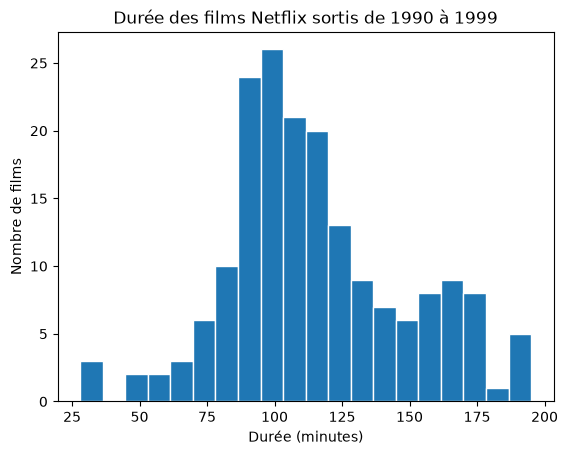

In [ ]:
# Garder les films dont l'année de sortie est comprise entre 1990 et 1999.
films_1990 = netflix_df.loc[
    netflix_df["type"].eq("Movie") & netflix_df["release_year"].between(1990, 1999)
]
durees = films_1990["duration"].dropna()

plt.figure()
plt.hist(durees, bins=20, edgecolor="white")
plt.title("Durée des films Netflix sortis de 1990 à 1999")
plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre de films")
plt.show()

# Le mode donne la durée exacte la plus fréquente.
duration = int(durees.mode().iloc[0])

films_action_courts = films_1990.loc[
    films_1990["genre"].eq("Action") & films_1990["duration"].lt(90)
]
short_movie_count = len(films_action_courts)

print(f"Films sortis de 1990 à 1999 : {len(films_1990)}")
print(f"Durée la plus fréquente : {duration} minutes")
print(f"Films d'action de moins de 90 minutes : {short_movie_count}")

Le filtre sur le type écarte les séries. Les deux années limites sont incluses. Le mode compte les occurrences de chaque durée en minutes, tandis que l’histogramme regroupe les durées en intervalles. Le filtre des films d’action courts exclut les films qui durent exactement 90 minutes.

In [ ]:
# @title ✅ Vérification 1/3 — Histogramme
print("Mini-projet 1 — histogramme :\n")

try:
    trace = bool(_TRACE["hist"])
except (NameError, KeyError, TypeError):
    trace = False

if trace:
    print("  ✅ Histogramme tracé")
else:
    print("  ❌ Aucun histogramme tracé — tracez la distribution des durées dans la cellule de code ci-dessus")

Mini-projet 1 — histogramme :

  ✅ Histogramme tracé


In [ ]:
# @title ✅ Vérification 2/3 — Durée la plus fréquente
import hashlib

print("Mini-projet 1 — duration :\n")

EMPREINTES = (
    "2da7378c6a53 6e5644c1d9a0 24dde732ae86 e96e1bf34abc 1c98935f604e 8cac4cb83aff "
    "b6f9002e4544 5411ab0fda13 00eeb5c60e8e a486e388837a f8e8d8699869"
).split()

try:
    valeur = int(duration)
    if isinstance(duration, bool) or valeur != float(duration):
        raise ValueError
    empreinte = hashlib.sha256(f"upjv-td07-mp1-{valeur}".encode()).hexdigest()[:12]
    if empreinte in EMPREINTES:
        print("  ✅ duration : durée correcte")
    else:
        print("  ❌ duration : durée hors de la plage attendue — relisez le pic de l'histogramme")
except NameError:
    print("  ❌ duration n'est pas défini — attribuez un entier à la variable duration")
except (ValueError, TypeError):
    print(f"  ❌ duration doit être un nombre entier de minutes — valeur reçue : {duration!r}")

Mini-projet 1 — duration :

  ✅ duration : durée correcte


In [ ]:
# @title ✅ Vérification 3/3 — Films d'action courts
import hashlib

print("Mini-projet 1 — short_movie_count :\n")

EMPREINTE_ATTENDUE = "7a9061358180"

try:
    valeur = int(short_movie_count)
    if isinstance(short_movie_count, bool) or valeur != float(short_movie_count):
        raise ValueError
    if hashlib.sha256(f"upjv-td07-mp1-{valeur}".encode()).hexdigest()[:12] == EMPREINTE_ATTENDUE:
        print("  ✅ short_movie_count : nombre correct")
    else:
        print("  ❌ short_movie_count : nombre incorrect — vérifiez le genre, les années 1990 à 1999 et le seuil de 90 minutes")
except NameError:
    print("  ❌ short_movie_count n'est pas défini — attribuez un entier à la variable short_movie_count")
except (ValueError, TypeError):
    print(f"  ❌ short_movie_count doit être un nombre entier — valeur reçue : {short_movie_count!r}")

Mini-projet 1 — short_movie_count :

  ✅ short_movie_count : nombre correct
